# Смотрим данные

In [9]:
!gdown 1KWlcYkMkDIZdATT2TTcnIfudNP-PSUci

Downloading...
From: https://drive.google.com/uc?id=1KWlcYkMkDIZdATT2TTcnIfudNP-PSUci
To: /content/titanic.csv
100% 61.2k/61.2k [00:00<00:00, 56.3MB/s]


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [11]:
data = pd.read_csv('titanic.csv', index_col='PassengerId')

In [12]:
data.head(10)

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S


In [13]:
data.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [14]:
data.isna().sum()

,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0
Cabin,687


<BarContainer object of 11 artists>

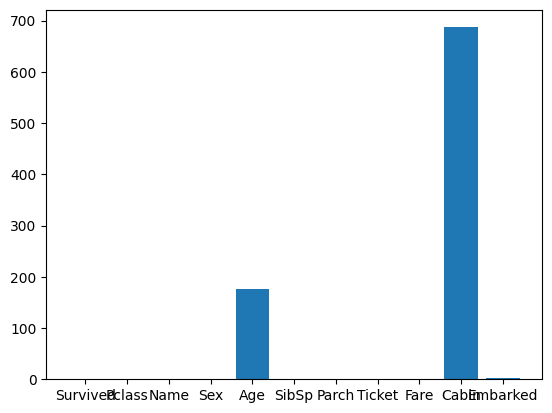

In [15]:
plt.bar(data.isna().sum().index, data.isna().sum().values)

<BarContainer object of 3 artists>

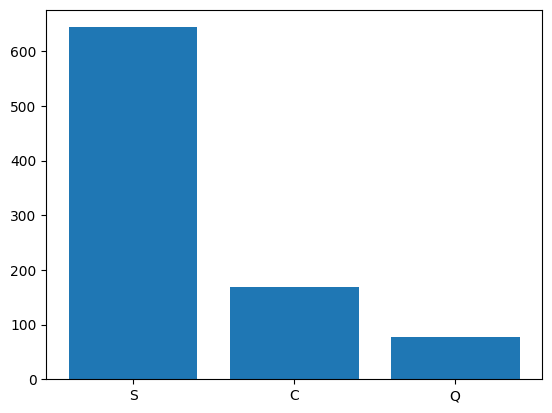

In [16]:
data['Embarked'].value_counts()
plt.bar(data['Embarked'].value_counts().index, data['Embarked'].value_counts().values)

In [17]:
data['Title'] = data.Name.str.extract(' ([A-Za-z]+)\.', expand=False)

pd.crosstab(data['Title'], data['Sex'])

<>:1: SyntaxWarning: invalid escape sequence '\.'
<>:1: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_4602/3680378333.py:1: SyntaxWarning: invalid escape sequence '\.'
  data['Title'] = data.Name.str.extract(' ([A-Za-z]+)\.', expand=False)


Sex,female,male
Title,,
Capt,0,1
Col,0,2
Countess,1,0
Don,0,1
Dr,1,6
Jonkheer,0,1
Lady,1,0
Major,0,2
Master,0,40


пояснение  
в меру того что у нас есть рарные погоняла в духе Rev Don итдитп то на них не получится поучиться ведь  
а) условный Jonkheer попадет в тест и модель впринципе не поймет че с этим делать  
б) их банально слишком мало на и так небольшом датасете  

поэтому я их просто объединяю в аля "группки"

In [18]:
data['Title'] = data['Title'].replace(['Lady', 'Countess','Capt', 'Col',\
 	'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')

data['Title'] = data['Title'].replace('Mlle', 'Miss')
data['Title'] = data['Title'].replace('Ms', 'Miss')
data['Title'] = data['Title'].replace('Mme', 'Mrs')

In [19]:
data.sample(5)

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title
PassengerId,,,,,,,,,,,,
251,0,3,"Reed, Mr. James George",male,NaN,0,0,362316,7.2500,NaN,S,Mr
727,1,2,"Renouf, Mrs. Peter Henry (Lillian Jefferys)",female,30.0,3,0,31027,21.0000,NaN,S,Mrs
484,1,3,"Turkula, Mrs. (Hedwig)",female,63.0,0,0,4134,9.5875,NaN,S,Mrs
45,1,3,"Devaney, Miss. Margaret Delia",female,19.0,0,0,330958,7.8792,NaN,Q,Miss
450,1,1,"Peuchen, Major. Arthur Godfrey",male,52.0,0,0,113786,30.5000,C104,S,Rare


# ПОдготавливаем данные

In [20]:
from sklearn.impute import SimpleImputer

In [21]:
imputer = SimpleImputer(missing_values=pd.NA, strategy='most_frequent')

data[['Embarked']] = imputer.fit_transform(data[['Embarked']])

нужно обработать age но там 177 пропусков из +-900 строк датасета, многовато

пояснение:  
заполняем пустоты с помощью KNN алгоритма работает также как на предикты только ищет соседей чтобы вставить ближайшее по смыслу значение, в идеале нужно проскейлить данные для точности но я этого не буду делать >.< но всё таки сделал

In [22]:
data['Fare'] = np.log1p(data['Fare'])

In [23]:
from sklearn.impute import KNNImputer

numimp = KNNImputer(missing_values=np.nan, n_neighbors=5)

data[['Age']] = numimp.fit_transform(data[['Age']])

In [24]:
data.isna().sum()

,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0
Cabin,687


супер

In [25]:
data.drop(columns=["Cabin", 'Name', 'Ticket'], inplace=True)

In [26]:
categorical_columns = ['Pclass', 'Sex', 'SibSp', 'Parch','Embarked', 'Title']

categorical_features = data[categorical_columns]

categorical_features.columns

unprocessed_cat_features = categorical_features.select_dtypes(include=[object]).columns.tolist()
data[unprocessed_cat_features]

,Sex,Embarked,Title
PassengerId,,,
1,male,S,Mr
2,female,C,Mrs
3,female,S,Miss
4,female,S,Mrs
5,male,S,Mr
...,...,...,...
887,male,S,Rare
888,female,S,Miss
889,female,S,Miss


In [27]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False)

encoded = ohe.fit_transform(data[unprocessed_cat_features])
newdata = pd.DataFrame(encoded, columns=ohe.get_feature_names_out(unprocessed_cat_features), index=data.index)

newdata

,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
PassengerId,,,,,,,,,,
1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
5,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
887,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
888,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
889,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [28]:
ohdata = pd.concat([data, newdata], axis=1)

ohdata.drop(unprocessed_cat_features, axis=1, inplace=True)

ohdata

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
PassengerId,,,,,,,,,,,,,,,,
1,0,3,22.000000,1,0,2.110213,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,1,1,38.000000,1,0,4.280593,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1,3,26.000000,0,0,2.188856,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,1,1,35.000000,1,0,3.990834,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
5,0,3,35.000000,0,0,2.202765,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
887,0,2,27.000000,0,0,2.639057,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
888,1,1,19.000000,0,0,3.433987,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
889,0,3,29.699118,1,2,3.196630,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [29]:
ohdata.isna().sum()

,0
Survived,0
Pclass,0
Age,0
SibSp,0
Parch,0
Fare,0
Sex_female,0
Sex_male,0
Embarked_C,0
Embarked_Q,0


# делим

In [30]:
from sklearn.model_selection import train_test_split

In [31]:
x = ohdata.drop(columns=['Survived'])
y = ohdata['Survived']

In [32]:
# ПОПРОБУЕМ ОТДЕЛЬНО ДЛЯ KNN СДЕЛАТЬ ДРУГИЕ ДАННЫЕ

#x = ohdata.drop(columns=['SibSp', 'Parch', 'Survived'])
#y = ohdata['Survived']

In [33]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

<Axes: >

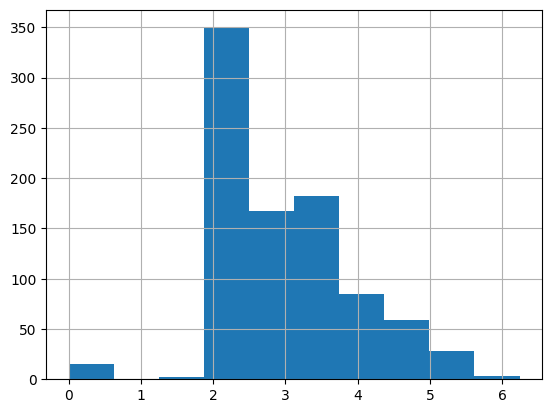

In [34]:
ohdata['Fare'].hist()

# скейлим?


да, скейлим \
для KNN и SVM нужно скальнуть числовые данные

In [35]:
from sklearn.preprocessing import StandardScaler, RobustScaler

есть вероятность что нужно Fare прологарифмировать

In [36]:
numeric = ['Pclass', 'Age',	'SibSp', 'Parch',	'Fare']

# numeric = ['Pclass', 'Age',	'Fare']

In [37]:
scaler = StandardScaler()

scaler.fit(x_train[numeric])

x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

x_train_scaled[numeric] = scaler.transform(x_train[numeric])
x_test_scaled[numeric] = scaler.transform(x_test[numeric])

теперь мы вроде реди учиться

In [38]:
ohdata

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
PassengerId,,,,,,,,,,,,,,,,
1,0,3,22.000000,1,0,2.110213,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,1,1,38.000000,1,0,4.280593,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1,3,26.000000,0,0,2.188856,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,1,1,35.000000,1,0,3.990834,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
5,0,3,35.000000,0,0,2.202765,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
887,0,2,27.000000,0,0,2.639057,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
888,1,1,19.000000,0,0,3.433987,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
889,0,3,29.699118,1,2,3.196630,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


<Axes: >

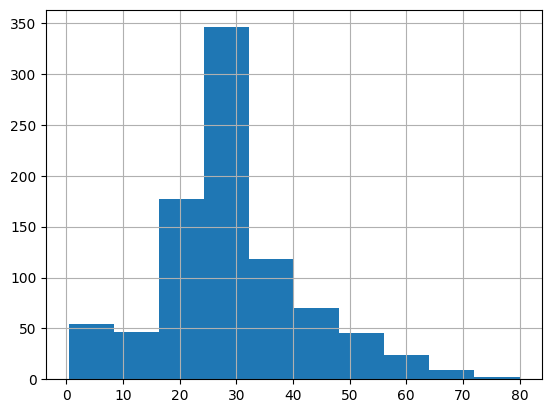

In [39]:
ohdata['Age'].hist()

# baseline

In [40]:
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score

In [41]:
from sklearn.metrics import confusion_matrix

In [42]:
pred_baseline = x_test['Sex_female']

In [43]:
acc_bl = accuracy_score(y_test, pred_baseline)
prec_bl = precision_score(y_test, pred_baseline)
rec_bl = recall_score(y_test, pred_baseline)
f1_baseline = f1_score(y_test, pred_baseline)
pd.Series([acc_bl, prec_bl, rec_bl, f1_baseline])

,0
0,0.776536
1,0.737705
2,0.652174
3,0.692308


In [44]:
cm_bl = confusion_matrix(y_test, pred_baseline)
cm_bl

array([[94, 16],
       [24, 45]])

# Decision Tree

In [45]:
from sklearn.tree import DecisionTreeClassifier

In [46]:
model_dtree = DecisionTreeClassifier(max_depth=3)

model_dtree.fit(x_train, y_train)

pred_dt = model_dtree.predict(x_test)

In [47]:
acc_train = accuracy_score(model_dtree.predict(x_train), y_train)

acc_test = accuracy_score(y_test, pred_dt)

acc_train - acc_test

-0.0009101751302491579

In [48]:
acc_dt = accuracy_score(y_test, pred_dt)
prec_dt = precision_score(y_test, pred_dt)
rec_dt = recall_score(y_test, pred_dt)
f1_dt = f1_score(y_test, pred_dt)

pd.Series([acc_dt, prec_dt, rec_dt, f1_dt])

,0
0,0.837989
1,0.812500
2,0.753623
3,0.781955


In [49]:
cm_dt = confusion_matrix(y_test, pred_dt)
cm_dt

array([[98, 12],
       [17, 52]])

# Random forest

In [50]:
from sklearn.ensemble import RandomForestClassifier

In [51]:
model_rforest = RandomForestClassifier(n_estimators=300, max_depth=6, oob_score=True)

model_rforest.fit(x_train, y_train)

pred_rf = model_rforest.predict(x_test)

In [52]:
acc1 = accuracy_score(y_train, model_rforest.predict(x_train))
acc2 = accuracy_score(y_test, pred_rf)
oob = model_rforest.oob_score_

acc2-oob

0.020510325779925953

In [53]:
acc_rf = accuracy_score(y_test, pred_rf)
prec_rf = precision_score(y_test, pred_rf)
rec_rf = recall_score(y_test, pred_rf)
f1_rf = f1_score(y_test, pred_rf)

pd.Series([acc_rf, prec_rf, rec_rf, f1_rf])

,0
0,0.849162
1,0.850000
2,0.739130
3,0.790698


In [54]:
cm_rf = confusion_matrix(y_test, pred_rf)
cm_rf

array([[101,   9],
       [ 18,  51]])

# Gradient Boosting

In [55]:
from sklearn.ensemble import GradientBoostingClassifier

In [76]:
model_gboost = GradientBoostingClassifier(n_estimators=300, max_depth=5, learning_rate=0.05)

model_gboost.fit(x_train, y_train)

pred_gb = model_gboost.predict(x_test)

In [77]:
acc_gb = accuracy_score(y_test, pred_gb)
prec_gb = precision_score(y_test, pred_gb)
rec_gb = recall_score(y_test, pred_gb)
f1_gb = f1_score(y_test, pred_gb)

pd.Series([acc_gb, prec_gb, rec_gb, f1_gb])

,0
0,0.843575
1,0.815385
2,0.768116
3,0.791045


In [58]:
cm_gb = confusion_matrix(y_test, pred_gb)
cm_gb

array([[98, 12],
       [17, 52]])

# Support Vector machine

In [59]:
from sklearn.svm import SVC

In [60]:
model_svm = SVC(C=0.2, class_weight='balanced', probability=True)

model_svm.fit(x_train_scaled, y_train)

pred_svm = model_svm.predict(x_test_scaled)

f1_svm = f1_score(y_test, pred_svm)
f1_svm

0.7761194029850746

In [61]:
acc_svm = accuracy_score(y_test, pred_svm)
prec_svm = precision_score(y_test, pred_svm)
rec_svm = recall_score(y_test, pred_svm)
f1_svm = f1_score(y_test, pred_svm)

pd.Series([acc_svm, prec_svm, rec_svm, f1_svm])

,0
0,0.832402
1,0.800000
2,0.753623
3,0.776119


In [62]:
cm_svm = confusion_matrix(y_test, pred_svm)
cm_svm

array([[97, 13],
       [17, 52]])

# K-nearest

In [63]:
from sklearn.neighbors import KNeighborsClassifier

In [64]:
model_knn = KNeighborsClassifier(n_neighbors=6, weights='distance', metric='manhattan')

model_knn.fit(x_train_scaled, y_train)

pred_knn = model_knn.predict(x_test_scaled)

f1_knn = f1_score(y_test, pred_knn)
f1_knn

0.7575757575757576

In [65]:
acc_knn = accuracy_score(y_test, pred_knn)
prec_knn = precision_score(y_test, pred_knn)
rec_knn = recall_score(y_test, pred_knn)
f1_knn = f1_score(y_test, pred_knn)

pd.Series([acc_knn, prec_knn, rec_knn, f1_knn])

,0
0,0.821229
1,0.793651
2,0.724638
3,0.757576


In [66]:
cm_knn = confusion_matrix(y_test, pred_knn)
cm_knn

array([[97, 13],
       [19, 50]])

# Feature importance

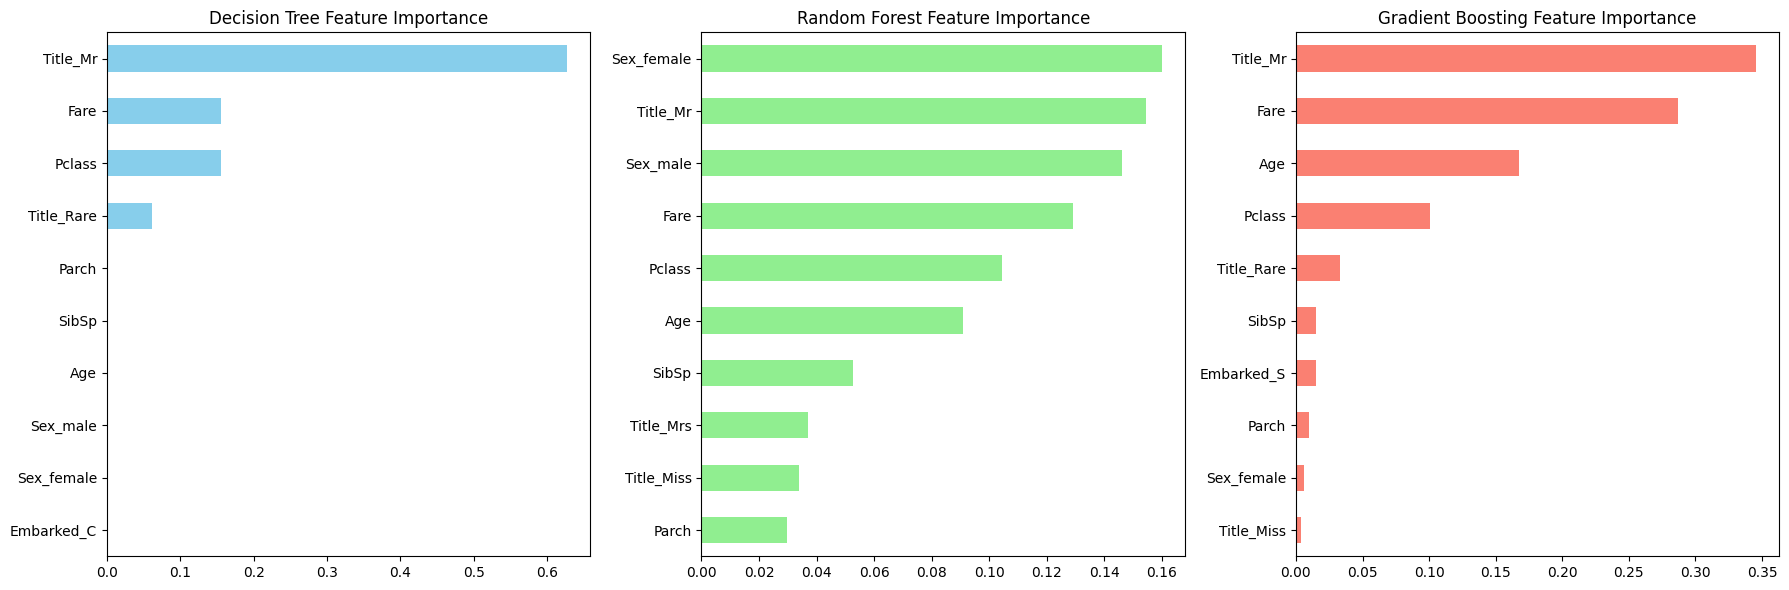

ТОП-10 признаков по важности во всех моделях:


,Decision Tree,Random Forest,Gradient Boosting
Age,0.000000,0.090842,0.167339
Embarked_C,0.000000,0.013969,0.003763
Embarked_Q,0.000000,0.010155,0.001710
Embarked_S,0.000000,0.017566,0.014844
Fare,0.155574,0.129124,0.287081
Parch,0.000000,0.029896,0.010008
Pclass,0.155052,0.104420,0.100884
Sex_female,0.000000,0.159990,0.006352
Sex_male,0.000000,0.146059,0.003921
SibSp,0.000000,0.052767,0.015393


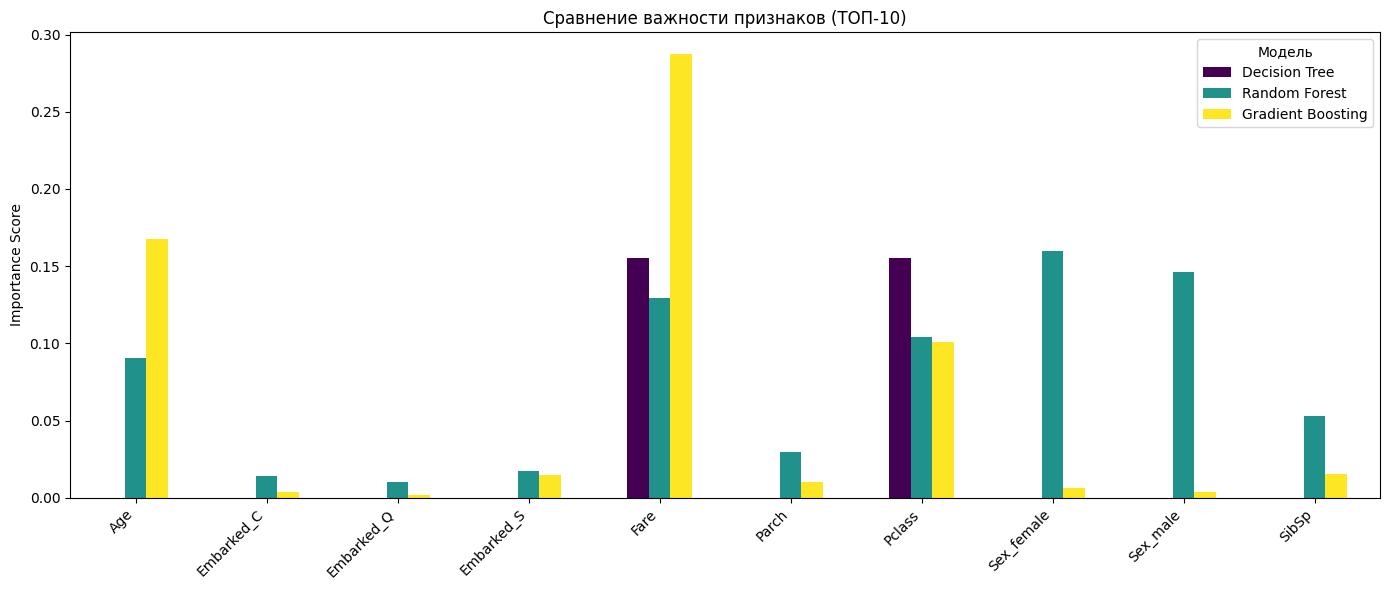

In [67]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Извлекаем важность признаков из моделей
feat_imp_dt = pd.Series(model_dtree.feature_importances_, index=x_train.columns).sort_values(ascending=False)
feat_imp_rf = pd.Series(model_rforest.feature_importances_, index=x_train.columns).sort_values(ascending=False)
feat_imp_gb = pd.Series(model_gboost.feature_importances_, index=x_train.columns).sort_values(ascending=False)

# 2. Визуализируем важность признаков для каждой модели
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Decision Tree
feat_imp_dt.head(10).plot(kind='barh', ax=axes[0], color='skyblue')
axes[0].set_title('Decision Tree Feature Importance')
axes[0].invert_yaxis() # Чтобы самый важный был сверху

# Random Forest
feat_imp_rf.head(10).plot(kind='barh', ax=axes[1], color='lightgreen')
axes[1].set_title('Random Forest Feature Importance')
axes[1].invert_yaxis()

# Gradient Boosting
feat_imp_gb.head(10).plot(kind='barh', ax=axes[2], color='salmon')
axes[2].set_title('Gradient Boosting Feature Importance')
axes[2].invert_yaxis()

plt.tight_layout()
plt.show()

# 3. Сводная таблица для сравнения
comparison_df = pd.DataFrame({
    'Decision Tree': feat_imp_dt,
    'Random Forest': feat_imp_rf,
    'Gradient Boosting': feat_imp_gb
})

# Выводим топ-10 общих важных признаков
print("ТОП-10 признаков по важности во всех моделях:")
display(comparison_df.head(10))

# Строим общий график для сравнения
comparison_df.head(10).plot(kind='bar', figsize=(14, 6), colormap='viridis')
plt.title('Сравнение важности признаков (ТОП-10)')
plt.ylabel('Importance Score')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Модель')
plt.tight_layout()
plt.show()

In [68]:
# Создаем датафрейм для анализа ошибок
error_analysis = x_test.copy()
error_analysis['Actual'] = y_test
error_analysis['Predicted'] = pred_rf

# 1. False Negatives: Выжили, но модель предсказала смерть (18 человек)
fn_cases = error_analysis[(error_analysis['Actual'] == 1) & (error_analysis['Predicted'] == 0)]
print("--- Пропущенные выжившие (False Negatives) ---")
display(fn_cases[['Sex_female', 'Pclass', 'Age', 'Fare', 'Title_Master', 'Title_Mrs']].head(5))

# 2. False Positives: Погибли, но модель предсказала выживание (9 человек)
fp_cases = error_analysis[(error_analysis['Actual'] == 0) & (error_analysis['Predicted'] == 1)]
print("\n--- Ложные выжившие (False Positives) ---")
display(fp_cases[['Sex_female', 'Pclass', 'Age', 'Fare', 'Title_Master', 'Title_Mrs']].head(5))

--- Пропущенные выжившие (False Negatives) ---


,Sex_female,Pclass,Age,Fare,Title_Master,Title_Mrs
PassengerId,,,,,,
554,0.0,3,22.000000,2.107178,0.0,0.0
713,0.0,1,48.000000,3.970292,0.0,0.0
456,0.0,3,29.000000,2.185579,0.0,0.0
18,0.0,2,29.699118,2.639057,0.0,0.0
680,0.0,1,36.000000,6.240917,0.0,0.0



--- Ложные выжившие (False Positives) ---


,Sex_female,Pclass,Age,Fare,Title_Master,Title_Mrs
PassengerId,,,,,,
746,0.0,1,70.000000,4.276666,0.0,0.0
298,1.0,1,2.000000,5.027492,0.0,0.0
503,1.0,3,29.699118,2.155152,0.0,0.0
579,1.0,3,29.699118,2.738146,0.0,1.0
594,1.0,3,29.699118,2.169054,0.0,0.0


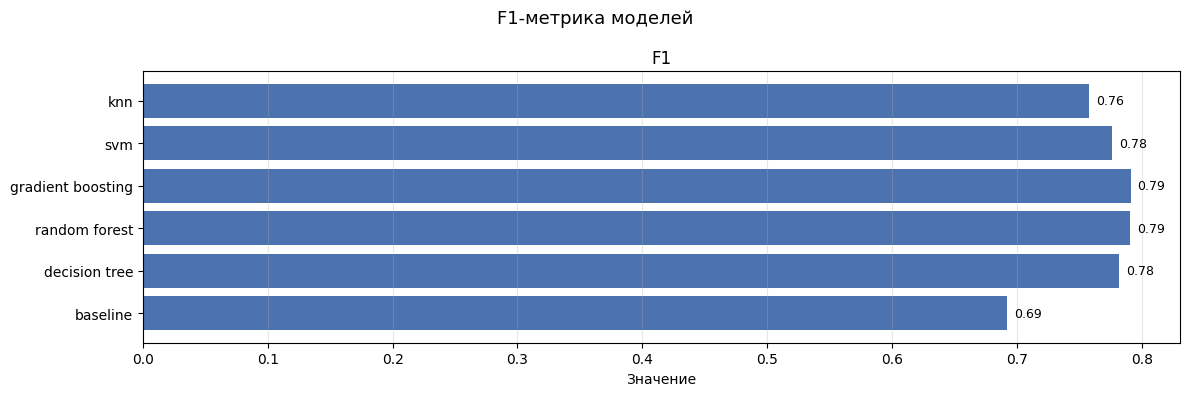

In [82]:
errors = pd.DataFrame({
    'model': ['baseline', 'decision tree', 'random forest', 'gradient boosting', 'svm', 'knn'],
    'f1':    [f1_baseline, f1_dt, f1_rf, f1_gb, f1_svm, f1_knn]
})

fig, ax = plt.subplots(figsize=(12, 4))

bars = ax.barh(errors['model'], errors['f1'], color='#4C72B0')
ax.set_title('F1')
ax.set_xlabel('Значение')
ax.grid(axis='x', alpha=0.3)

for bar in bars:
    w = bar.get_width()
    ax.annotate(f'{w:.2f}',
                xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0), textcoords='offset points',
                va='center', fontsize=9)

plt.suptitle('F1-метрика моделей', fontsize=13)
plt.tight_layout()
plt.show()